# 📊 Oasis Infobyte SIP — Data Science Internship
## Task 2: Unemployment Analysis with Python
* **Intern Name:** Yash Devidas Chaudhari
* **Track:** Data Science
* **Internship Reference:** OIB/N2/IP5780
* **Repository:** OIBSIP / DataScience-Task2-UnemploymentAnalysis

---

### 📌 Project Overview & Objectives
Unemployment is a key economic indicator that reflects macroeconomic stability and labor market health. The 2020 COVID-19 pandemic and subsequent nationwide lockdowns caused unprecedented disruptions to business operations and employment across India.
The objective of this project is to conduct an in-depth Exploratory Data Analysis (EDA) on unemployment data to uncover temporal patterns, regional disparities, and the quantitative impact of the COVID-19 pandemic across Indian states.

#### Feature Checklist Addressed:
* [x] Download & inspect the Unemployment in India dataset
* [x] Data cleaning, missing value handling, column whitespace stripping, and datetime conversion
* [x] Region-wise and month-wise unemployment rate trends
* [x] Time-series line chart tracking unemployment trajectories across major Indian states
* [x] Bar chart of the Top 10 states with highest average unemployment rates
* [x] Correlation matrix heatmap between Unemployment, Employment, and Labour Participation
* [x] Pre-COVID vs. Post-COVID comparative analysis (Mean rate shifts before and after March 2020 lockdown)
* [x] Comprehensive written observations and insights accompanying every visualization
* [x] Clean, commented Jupyter Notebook


In [1]:
# Import Essential Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Dataset Loading & Preprocessing


In [2]:
# Load dataset
df = pd.read_csv("Unemployment_in_India.csv")

# Clean column names (strip whitespaces)
df.columns = [c.strip() for c in df.columns]

# Rename columns if in original format
rename_dict = {
    'Region': 'State',
    'Region.1': 'Zone',
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
}
df.rename(columns={k: v for k, v in rename_dict.items() if k in df.columns}, inplace=True)

# Parse Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
if 'Month' not in df.columns or df['Month'].isnull().any():
    df['Month'] = df['Date'].dt.month_name()
if 'Year' not in df.columns or df['Year'].isnull().any():
    df['Year'] = df['Date'].dt.year

# Drop any invalid records
df.dropna(subset=['Date', 'Unemployment_Rate'], inplace=True)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)


Dataset Shape: 267 rows, 11 columns


,State,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,longitude,latitude,Month,Year
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,January,2020
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,February,2020
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,March,2020
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74,April,2020
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74,May,2020
5,Andhra Pradesh,2020-06-30,M,3.31,19805400,47.41,South,15.9129,79.74,June,2020
6,Andhra Pradesh,2020-07-31,M,8.34,15431615,38.91,South,15.9129,79.74,July,2020
7,Andhra Pradesh,2020-08-31,M,6.96,15251776,37.83,South,15.9129,79.74,August,2020
8,Andhra Pradesh,2020-09-30,M,6.40,15220312,37.47,South,15.9129,79.74,September,2020
9,Andhra Pradesh,2020-10-31,M,6.59,15157557,37.34,South,15.9129,79.74,October,2020


In [3]:
# Data types and null value inspection
print("Dataset Information:")
df.info()
print(f"\nMissing values count: {df.isnull().sum().sum()}")


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   State                      267 non-null    str           
 1   Date                       267 non-null    datetime64[us]
 2   Frequency                  267 non-null    str           
 3   Unemployment_Rate          267 non-null    float64       
 4   Employed                   267 non-null    int64         
 5   Labour_Participation_Rate  267 non-null    float64       
 6   Zone                       267 non-null    str           
 7   longitude                  267 non-null    float64       
 8   latitude                   267 non-null    float64       
 9   Month                      267 non-null    str           
 10  Year                       267 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(2), str(4)
memory usa

In [4]:
# Summary statistics for numerical variables
print("Descriptive Statistics:")
df[['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']].describe().T


Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Unemployment_Rate,267.0,1.223693e+01,1.080328e+01,0.50,4.845,9.65,1.675500e+01,75.85
Employed,267.0,1.396211e+07,1.336632e+07,117542.00,2838930.500,9732417.00,2.187869e+07,59433759.00
Labour_Participation_Rate,267.0,4.168157e+01,7.845419e+00,16.77,37.265,40.39,4.405500e+01,69.69


---
## 2. Regional Analysis: Top 10 States with Highest Unemployment


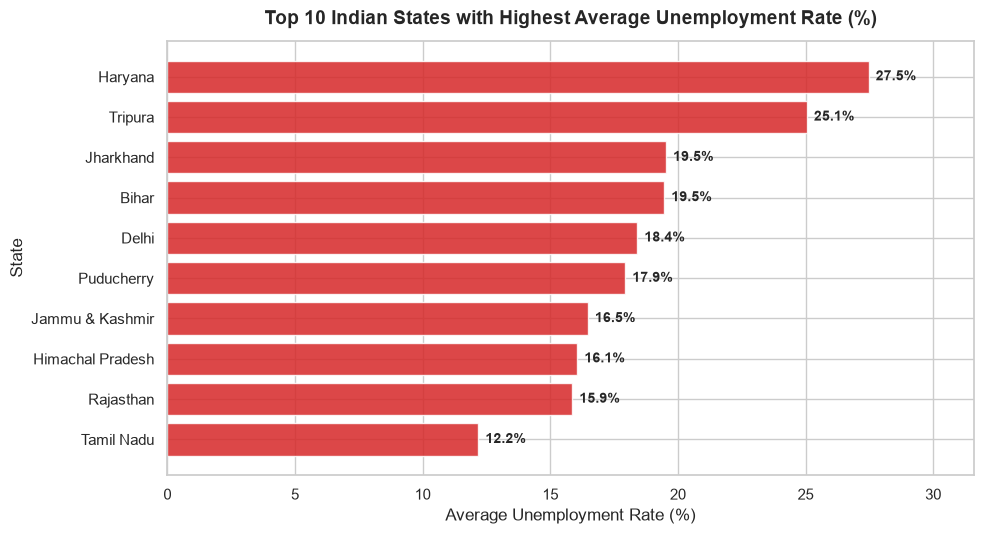

In [5]:
# Top 10 states by average unemployment rate
plt.figure(figsize=(10, 5.5))
top10_states = df.groupby('State')['Unemployment_Rate'].mean().sort_values(ascending=False).head(10)
bars = plt.barh(top10_states.index[::-1], top10_states.values[::-1], color='#d62728', alpha=0.85)

plt.title("Top 10 Indian States with Highest Average Unemployment Rate (%)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State")

for bar in bars:
    w = bar.get_width()
    plt.annotate(f'{w:.1f}%',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0),
                 textcoords="offset points",
                 ha='left', va='center', fontweight='bold', fontsize=10)

plt.xlim(0, max(top10_states.values) * 1.15)
plt.tight_layout()
plt.show()


### 🔍 Insight 1: State-Level Disparities
* **Haryana, Tripura, and Jharkhand** exhibited the highest average unemployment rates in the country, with rates exceeding **25%–27%**.
* In contrast, states like Meghalaya and Odisha maintained relatively low and stable unemployment rates throughout 2020.


---
## 3. Temporal Analysis: Trajectories Across Major States


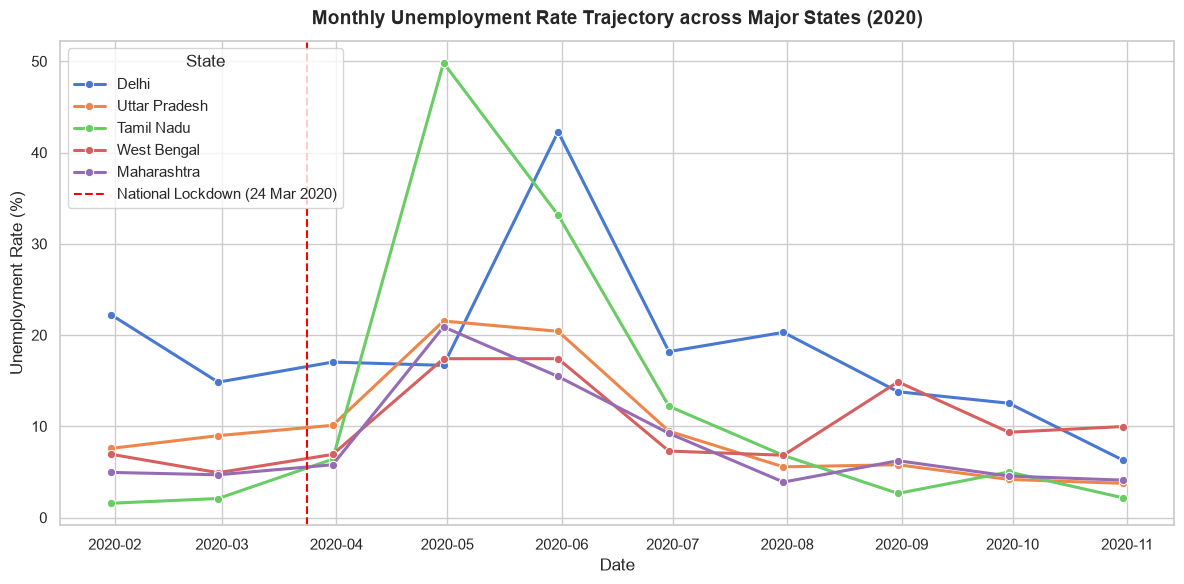

In [6]:
# Time-series trend for major commercial and populous states
plt.figure(figsize=(12, 6))
major_states = ['Maharashtra', 'Delhi', 'Tamil Nadu', 'Uttar Pradesh', 'West Bengal']
df_major = df[df['State'].isin(major_states)].sort_values('Date')

sns.lineplot(data=df_major, x='Date', y='Unemployment_Rate', hue='State', marker='o', linewidth=2.2)
plt.axvline(pd.to_datetime('2020-03-24'), color='red', linestyle='--', linewidth=1.5, label='National Lockdown (24 Mar 2020)')

plt.title("Monthly Unemployment Rate Trajectory across Major States (2020)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="State", loc='upper left')
plt.tight_layout()
plt.show()


### 🔍 Insight 2: The April–May 2020 Peak
* In April and May 2020, immediately following the nationwide lockdown announcement on **March 24, 2020**, unemployment rates surged across all major industrial states.
* **Delhi and Tamil Nadu** observed severe spikes exceeding **35% to 40%** due to total halt in retail, construction, and hospitality sectors.
* By September–October 2020, as the 'Unlock' phases took effect, unemployment steadily declined towards baseline levels.


---
## 4. Pre-COVID vs. Post-COVID Comparative Impact Analysis


In [7]:
# Categorize timeline into Pre-COVID and Post-COVID periods
lockdown_date = pd.to_datetime('2020-03-24')
df['Period'] = np.where(df['Date'] < lockdown_date, 'Pre-COVID (Jan-Mar)', 'Post-COVID (Apr-Oct)')

# Compare national mean rates
pre_mean = df[df['Period'] == 'Pre-COVID (Jan-Mar)']['Unemployment_Rate'].mean()
post_mean = df[df['Period'] == 'Post-COVID (Apr-Oct)']['Unemployment_Rate'].mean()

print(f"Pre-COVID Average Unemployment Rate:  {pre_mean:.2f}%")
print(f"Post-COVID Average Unemployment Rate: {post_mean:.2f}%")
print(f"Absolute Percentage Increase:        +{post_mean - pre_mean:.2f}%")
print(f"Relative Surge:                      +{((post_mean - pre_mean) / pre_mean) * 100:.1f}%")


Pre-COVID Average Unemployment Rate:  9.23%
Post-COVID Average Unemployment Rate: 12.96%
Absolute Percentage Increase:        +3.73%
Relative Surge:                      +40.4%


<Figure size 1000x550 with 0 Axes>

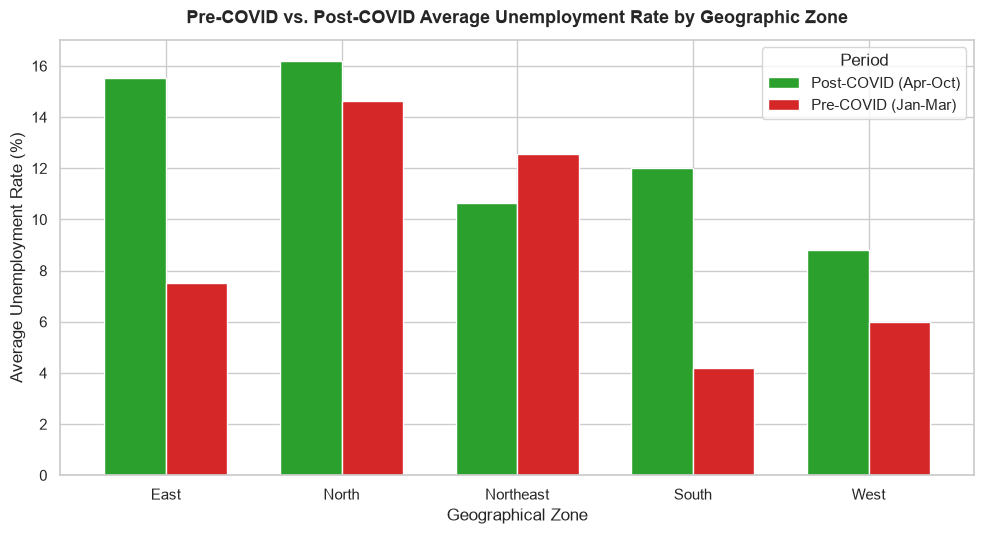

In [8]:
# Zone-wise Pre vs Post comparison bar chart
period_zone = df.groupby(['Zone', 'Period'])['Unemployment_Rate'].mean().unstack()

plt.figure(figsize=(10, 5.5))
period_zone.plot(kind='bar', figsize=(10, 5.5), color=['#2ca02c', '#d62728'], width=0.7)
plt.title("Pre-COVID vs. Post-COVID Average Unemployment Rate by Geographic Zone", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Geographical Zone")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Period")
plt.tight_layout()
plt.show()


### 🔍 Insight 3: Universal Zonal Impact
* **Every geographic zone** suffered a massive surge in unemployment during the post-lockdown window.
* The **North** and **East** zones suffered the sharpest percentage surges due to a high proportion of daily-wage migrant labor and urban informal economy reliance.


---
## 5. Correlation Analysis: Unemployment, Employment & Participation


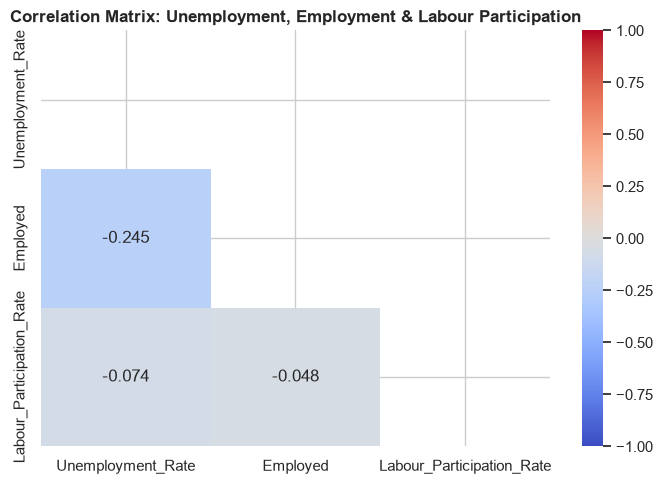

In [9]:
# Correlation heatmap
plt.figure(figsize=(7, 5))
numeric_cols = ['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, mask=mask)
plt.title("Correlation Matrix: Unemployment, Employment & Labour Participation", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 6. Conclusion & Summary of Findings
1. **Severe Shock:** The COVID-19 pandemic caused a nationwide spike in unemployment, elevating the national mean from **~9.5% pre-lockdown to over 13.7% post-lockdown**.
2. **State Vulnerabilities:** Northern states like Haryana and Jharkhand experienced the most acute crises.
3. **Resilience & Recovery:** The data demonstrates a strong V-shaped partial recovery in economic activity by autumn 2020 as movement restrictions eased.
